<a href="https://colab.research.google.com/github/millerfabiancanon-a11y/Business_Analytics/blob/main/An%C3%A1lisis_predictivo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller ETL + Análisis predictivo de ventas (TecnoAndes)

Este notebook tiene **dos partes**:

1. **Parte 1 – ETL**: tomamos tres archivos con errores (ventas, clientes y productos), los limpiamos y los cargamos en una base de datos.
2. **Parte 2 – Análisis predictivo**: con los datos ya limpios elegimos variables, entrenamos modelos, graficamos resultados y los interpretamos.

**Cómo usarlo:** ejecuta las celdas en orden, de arriba hacia abajo (Entorno de ejecución → Ejecutar todo). Cada celda de código tiene antes una celda de texto que explica qué hace.

**Contenido**
- Parte 1: ETL (extraer, perfilar, limpiar, validar, cargar)
- Parte 2A: predecir el **total** de cada venta
- Parte 2B: predecir la **demanda** (unidades por producto y mes)
- Conclusiones generales

# PARTE 1 – ETL

ETL significa **E**xtract (extraer), **T**ransform (transformar) y **L**oad (cargar). La idea es partir de datos "sucios" y dejarlos listos para analizar.

## 1.1 Generar los datos de entrada

Esta celda **crea el archivo `generar_datos.py`** (`%%writefile` guarda el contenido de la celda como archivo). Ese script fabrica tres archivos con **errores intencionales** para practicar la limpieza:

| Archivo | Formato | Errores que trae |
|---|---|---|
| `ventas.csv` | CSV con `;` | duplicados, fechas en 3 formatos, cantidades negativas o vacías, descuentos vacíos, canal con mayúsculas distintas, un cliente que no existe |
| `clientes.json` | JSON | ciudades escritas de varias formas, nombres en mayúsculas, emails vacíos |
| `productos.xlsx` | Excel | categorías con mayúsculas y espacios distintos |

La semilla aleatoria (`random.seed(42)`) es fija: los datos salen **siempre iguales**, así los resultados de este notebook se pueden reproducir.

In [1]:
%%writefile generar_datos.py
"""
Genera los datos de entrada del Taller ETL, con errores de calidad intencionales.

Uso (desde la raíz del repositorio):
    python src/generar_datos.py

Crea la carpeta datos/ con: ventas.csv, clientes.json y productos.xlsx.
La semilla aleatoria es fija, por lo que los datos son siempre los mismos.
"""
import json
import os
import random

import pandas as pd

random.seed(42)
os.makedirs("datos", exist_ok=True)

# ---------- PRODUCTOS (Excel) ----------
productos = pd.DataFrame({
    "id_producto": [f"P{i:03d}" for i in range(1, 11)],
    "nombre": ["Portátil", "Mouse", "Teclado", "Monitor 24\"", "Audífonos",
               "Impresora", "Tablet", "Disco SSD 1TB", "Cámara Web", "Router WiFi"],
    "categoria": ["Computo", "Accesorios", "accesorios", "Computo", "Audio",
                  "Oficina", "Computo", "Almacenamiento", "Accesorios ", "Redes"],
    "precio_unitario": [3200000, 45000, 120000, 780000, 150000,
                        650000, 1400000, 380000, 95000, 210000],
})
productos.to_excel("datos/productos.xlsx", index=False, sheet_name="catalogo")

# ---------- CLIENTES (JSON) ----------
nombres = ["Ana Gómez", "Luis Pérez", "María Rodríguez", "Carlos López", "Laura Martínez",
           "Jorge Ramírez", "Sofía Torres", "Andrés Díaz", "Valentina Ruiz", "Felipe Castro",
           "Camila Herrera", "Santiago Moreno", "Daniela Rojas", "Juan Vargas", "Paula Ortiz"]
ciudades = ["Bogotá", "bogota", "Medellín", "MEDELLIN", " Cali", "Barranquilla",
            "Bucaramanga", "Cartagena", "Bogotá ", "Pereira"]
clientes = []
for i, n in enumerate(nombres, start=1):
    clientes.append({
        "id_cliente": i,
        "nombre": n if i % 5 else n.upper(),          # algunos en mayúsculas
        "email": None if i in (4, 11) else f"{n.split()[0].lower()}{i}@correo.com",
        "ciudad": random.choice(ciudades),
        "fecha_registro": f"2024-{random.randint(1, 12):02d}-{random.randint(1, 28):02d}",
    })
with open("datos/clientes.json", "w", encoding="utf-8") as f:
    json.dump(clientes, f, ensure_ascii=False, indent=2)

# ---------- VENTAS (CSV) ----------
formatos = ["%Y-%m-%d", "%d/%m/%Y", "%Y/%m/%d"]          # fechas inconsistentes
filas = []
for i in range(1, 501):
    fecha = pd.Timestamp("2025-01-01") + pd.Timedelta(days=random.randint(0, 364))
    cantidad = random.randint(1, 5)
    if i % 37 == 0:
        cantidad = -cantidad                                # cantidades negativas (error)
    filas.append({
        "id_venta": i,
        "fecha": fecha.strftime(random.choice(formatos)),
        "id_cliente": random.randint(1, 16),               # el 16 no existe (huérfano)
        "id_producto": random.choice(productos["id_producto"]),
        "cantidad": cantidad if i % 53 else None,          # nulos
        "descuento": random.choice(["0%", "5%", "10%", "", "15%"]),
        "canal": random.choice(["Web", "web", "Tienda", "TIENDA", "App"]),
    })
ventas = pd.DataFrame(filas)
ventas = pd.concat([ventas, ventas.sample(15, random_state=1)])   # duplicados
ventas = ventas.sample(frac=1, random_state=7)                    # desordenar
ventas.to_csv("datos/ventas.csv", index=False, sep=";", encoding="utf-8")

print("Datos generados en ./datos:")
for f in sorted(os.listdir("datos")):
    print("  -", f)

Writing generar_datos.py


## 1.2 Ejecutar el generador y ver los archivos crudos

- `!python generar_datos.py` ejecuta el script (el `!` corre un comando de terminal).
- Importamos las librerías que usaremos: `pandas` (tablas), `json`, `sqlite3` (base de datos), `unicodedata` (quitar tildes) y `os`.
- `!head` muestra las primeras líneas de los archivos, **tal como llegan**, sin limpiar.

In [2]:
!python generar_datos.py

import os, json, sqlite3, unicodedata, logging
import pandas as pd
pd.set_option("display.max_columns", 20)

# Vistazo a los archivos crudos, tal como llegan
!head -n 5 datos/ventas.csv
!head -n 9 datos/clientes.json

Datos generados en ./datos:
  - clientes.json
  - productos.xlsx
  - ventas.csv
id_venta;fecha;id_cliente;id_producto;cantidad;descuento;canal
490;2025-05-20;7;P003;2.0;15%;Web
430;2025/03/27;1;P004;1.0;10%;Web
83;2025-12-06;14;P003;1.0;;web
121;2025/12/19;13;P005;3.0;15%;App
[
  {
    "id_cliente": 1,
    "nombre": "Ana Gómez",
    "email": "ana1@correo.com",
    "ciudad": "bogota",
    "fecha_registro": "2024-01-24"
  },
  {


## 1.3 EXTRAER: leer los tres archivos

Cada formato se lee distinto:
- **CSV**: hay que indicar el separador (`sep=";"`) y la codificación (`utf-8`) o las tildes salen mal.
- **JSON**: es una lista de objetos; se convierte en tabla con `pd.DataFrame`.
- **Excel**: se indica la hoja (`sheet_name="catalogo"`).

Nombramos los datos originales con `_raw` ("crudo") para conservarlos intactos.

**Resultado:** 515 ventas (incluye 15 duplicadas), 15 clientes y 10 productos.

In [3]:
# 1.1 CSV: atención al separador ';' y a la codificación
ventas_raw = pd.read_csv("datos/ventas.csv", sep=";", encoding="utf-8")

# 1.2 JSON: lista de objetos -> DataFrame
with open("datos/clientes.json", encoding="utf-8") as f:
    clientes_raw = pd.DataFrame(json.load(f))
# (alternativa: pd.read_json("datos/clientes.json"))

# 1.3 Excel: se indica la hoja
productos_raw = pd.read_excel("datos/productos.xlsx", sheet_name="catalogo")

for nombre, df in [("ventas", ventas_raw), ("clientes", clientes_raw), ("productos", productos_raw)]:
    print(f"{nombre:10s} -> {df.shape[0]:4d} filas, {df.shape[1]} columnas")

ventas     ->  515 filas, 7 columnas
clientes   ->   15 filas, 5 columnas
productos  ->   10 filas, 4 columnas


## 1.4 Perfilar: revisar la calidad antes de limpiar

`perfilar()` arma una tabla resumen por columna: tipo de dato, cuántos nulos, porcentaje de nulos, valores únicos y un ejemplo. Además cuenta los duplicados exactos.

**Qué vemos en `ventas`:** 15 filas duplicadas, 9 cantidades vacías y 135 descuentos vacíos (26%). La columna `fecha` es texto (`object`) y no fecha, y `canal` tiene 5 valores cuando debería tener 3.

In [4]:
def perfilar(df, nombre):
    print(f"=== {nombre}: {len(df)} filas | duplicados exactos: {df.duplicated().sum()} ===")
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "% nulos": (df.isna().mean() * 100).round(1),
        "únicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

perfilar(ventas_raw, "ventas")

=== ventas: 515 filas | duplicados exactos: 15 ===


,tipo,nulos,% nulos,únicos,ejemplo
id_venta,int64,0,0.0,500,490
fecha,object,0,0.0,408,2025-05-20
id_cliente,int64,0,0.0,16,7
id_producto,object,0,0.0,10,P003
cantidad,float64,9,1.7,10,2.0
descuento,object,135,26.2,4,15%
canal,object,0,0.0,5,Web


## 1.5 Revisar los valores de las columnas de texto

Miramos los valores distintos para descubrir **inconsistencias**:
- `canal`: `Web` y `web`, `Tienda` y `TIENDA`.
- `ciudades`: `bogota`, `Bogotá`, `Bogotá ` (con espacio), ` Cali`.
- `categorías`: `Accesorios`, `accesorios`, `Accesorios `.
- Hay 13 cantidades negativas y las fechas vienen en formatos mezclados.

In [5]:
# Valores distintos en las columnas de texto
for col in ["canal", "descuento"]:
    print(col, "->", sorted(ventas_raw[col].dropna().unique()))
print("ciudades ->", clientes_raw["ciudad"].unique())
print("categorías ->", productos_raw["categoria"].unique())
print("cantidades negativas:", (ventas_raw["cantidad"] < 0).sum())
print("muestra de fechas:", ventas_raw["fecha"].sample(6, random_state=0).tolist())

canal -> ['App', 'TIENDA', 'Tienda', 'Web', 'web']
descuento -> ['0%', '10%', '15%', '5%']
ciudades -> ['bogota' ' Cali' 'Medellín' 'Bogotá ' 'Bucaramanga' 'Cartagena' 'Bogotá'
 'Barranquilla']
categorías -> ['Computo' 'Accesorios' 'accesorios' 'Audio' 'Oficina' 'Almacenamiento'
 'Accesorios ' 'Redes']
cantidades negativas: 13
muestra de fechas: ['2025/03/20', '2025-04-09', '2025/09/27', '29/05/2025', '2025/03/08', '22/07/2025']


## 1.6 TRANSFORMAR: preparar copias de trabajo y una bitácora

Trabajamos sobre **copias** (`.copy()`) para no tocar los datos originales. `log_calidad` es una lista donde `registrar()` anota **cuántas filas afectó cada paso de limpieza** (sirve de auditoría).

In [7]:
ventas = ventas_raw.copy()
clientes = clientes_raw.copy()
productos = productos_raw.copy()
log_calidad = []   # bitácora de las acciones realizadas, para auditoría

def registrar(paso, antes, despues):
    log_calidad.append({"paso": paso, "antes": antes, "después": despues, "afectados": antes - despues})

## 1.7 Eliminar duplicados

Se aplican dos reglas: quitar filas **idénticas** y asegurar que `id_venta` (la clave de negocio) sea **única**.

**Resultado:** 515 → 500 filas (15 duplicados eliminados).

In [8]:
antes = len(ventas)
ventas = ventas.drop_duplicates()                       # duplicados exactos
ventas = ventas.drop_duplicates(subset="id_venta")      # la clave de negocio debe ser única
registrar("Eliminar duplicados", antes, len(ventas))
print(f"{antes} -> {len(ventas)} filas")

515 -> 500 filas


## 1.8 Unificar las fechas

Las fechas vienen en tres formatos (`2025-05-20`, `20/05/2025`, `2025/05/20`). `parsear_fecha()` prueba cada formato y convierte lo que puede; lo que no se reconoce queda vacío (`errors="coerce"`).

**Resultado:** 0 fechas no reconocidas, todas entre el 3 de enero y el 29 de diciembre de 2025.

In [9]:
def parsear_fecha(serie):
    resultado = pd.Series(pd.NaT, index=serie.index)
    for fmt in ["%Y-%m-%d", "%d/%m/%Y", "%Y/%m/%d"]:
        faltan = resultado.isna()
        resultado[faltan] = pd.to_datetime(serie[faltan], format=fmt, errors="coerce")
    return resultado

ventas["fecha"] = parsear_fecha(ventas["fecha"])
print("Fechas no reconocidas:", ventas["fecha"].isna().sum())
print("Rango:", ventas["fecha"].min().date(), "a", ventas["fecha"].max().date())

Fechas no reconocidas: 0
Rango: 2025-01-03 a 2025-12-29


## 1.9 Tratar cantidades inválidas

Una venta con cantidad **vacía o menor/igual a 0** no es confiable. En vez de borrarla en silencio, la guardamos en la tabla `rechazos` con su motivo, y la sacamos de `ventas`. Luego `cantidad` pasa a número entero.

**Resultado:** 13 filas con cantidad ≤ 0 y 9 con cantidad nula.

In [10]:
antes = len(ventas)
rechazos = ventas[ventas["cantidad"].isna() | (ventas["cantidad"] <= 0)].copy()
rechazos["motivo"] = rechazos["cantidad"].apply(lambda x: "cantidad nula" if pd.isna(x) else "cantidad <= 0")

ventas = ventas.drop(rechazos.index)
ventas["cantidad"] = ventas["cantidad"].astype(int)
registrar("Cantidad nula o <= 0", antes, len(ventas))
rechazos["motivo"].value_counts()

,count
motivo,
cantidad <= 0,13
cantidad nula,9


## 1.10 Convertir el descuento a número

El descuento viene como texto (`"10%"`) o vacío. Los vacíos se interpretan como **0%** y el texto se convierte a decimal (`"10%"` → `0.10`) para poder calcular con él.

In [11]:
ventas["descuento"] = (
    ventas["descuento"]
      .fillna("0%")
      .replace("", "0%")
      .str.rstrip("%")
      .astype(float) / 100          # "10%" -> 0.10
)
ventas["descuento"].value_counts().sort_index()

,count
descuento,
0.00,216
0.05,75
0.10,94
0.15,93


## 1.11 Normalizar texto (ciudades, categorías, canales)

- `normalizar()` pasa a minúsculas, quita espacios y tildes.
- `mapa_ciudades` traduce cada versión a su nombre correcto (`bogota` → `Bogotá`).
- Nombres en formato título, emails vacíos con un valor por defecto, y fechas de registro como fecha.
- `categoria` y `canal` se limpian con `strip()` (espacios) y `capitalize()` (mayúscula inicial).

**Resultado:** 6 ciudades, 6 categorías y 3 canales, todos consistentes.

In [12]:
def normalizar(texto):
    """Minúsculas, sin espacios extremos y sin tildes."""
    texto = str(texto).strip().lower()
    return "".join(c for c in unicodedata.normalize("NFD", texto) if unicodedata.category(c) != "Mn")

mapa_ciudades = {
    "bogota": "Bogotá", "medellin": "Medellín", "cali": "Cali", "barranquilla": "Barranquilla",
    "bucaramanga": "Bucaramanga", "cartagena": "Cartagena", "pereira": "Pereira",
}
clientes["ciudad"] = clientes["ciudad"].map(normalizar).map(mapa_ciudades)
clientes["nombre"] = clientes["nombre"].str.title()
clientes["email"] = clientes["email"].fillna("sin_email@desconocido.com")
clientes["fecha_registro"] = pd.to_datetime(clientes["fecha_registro"])

productos["categoria"] = productos["categoria"].str.strip().str.capitalize()
ventas["canal"] = ventas["canal"].str.strip().str.capitalize()

print("Ciudades:", clientes["ciudad"].unique())
print("Categorías:", productos["categoria"].unique())
print("Canales:", ventas["canal"].unique())

Ciudades: ['Bogotá' 'Cali' 'Medellín' 'Bucaramanga' 'Cartagena' 'Barranquilla']
Categorías: ['Computo' 'Accesorios' 'Audio' 'Oficina' 'Almacenamiento' 'Redes']
Canales: ['Web' 'App' 'Tienda']


## 1.12 Integridad: ventas de clientes que no existen

`merge(..., indicator=True)` cruza ventas con clientes y marca las que no encuentran pareja. Aparece el **cliente 16**, que no existe (23 ventas). Esas filas van a `rechazos` con el motivo "cliente inexistente". El `assert` confirma que todos los productos sí existen: si no fuera así, el notebook se detiene con un error.

In [13]:
chequeo = ventas.merge(clientes[["id_cliente"]], on="id_cliente", how="left", indicator=True)
huerfanas = chequeo[chequeo["_merge"] == "left_only"]
print("Ventas con cliente inexistente:", len(huerfanas), "-> ids:", huerfanas["id_cliente"].unique())

antes = len(ventas)
h = ventas[ventas["id_cliente"].isin(huerfanas["id_cliente"])].assign(motivo="cliente inexistente")
rechazos = pd.concat([rechazos, h])
ventas = ventas.drop(h.index)
registrar("Cliente inexistente", antes, len(ventas))

assert ventas["id_producto"].isin(productos["id_producto"]).all(), "Existen productos huérfanos"

Ventas con cliente inexistente: 23 -> ids: [16]


## 1.13 Unir las tablas y crear columnas calculadas

Con `merge` se une cada venta con la información de su producto y de la ciudad de su cliente. Luego calculamos:
- `subtotal = cantidad × precio_unitario`
- `valor_descuento = subtotal × descuento`
- `total = subtotal − valor_descuento`
- `anio`, `mes`, `dia_semana`, sacados de la fecha.

El resultado es la tabla **`df`**: una fila por venta limpia (455 filas). **Es la que usaremos en la Parte 2.**

In [14]:
df = (ventas
      .merge(productos, on="id_producto", how="inner")
      .merge(clientes[["id_cliente", "ciudad"]], on="id_cliente", how="inner"))

df["subtotal"] = df["cantidad"] * df["precio_unitario"]
df["valor_descuento"] = (df["subtotal"] * df["descuento"]).round(0)
df["total"] = df["subtotal"] - df["valor_descuento"]
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month
df["dia_semana"] = df["fecha"].dt.day_name()
df = df.sort_values(["fecha", "id_venta"]).reset_index(drop=True)
df.head()

,id_venta,fecha,id_cliente,id_producto,cantidad,descuento,canal,nombre,categoria,precio_unitario,ciudad,subtotal,valor_descuento,total,anio,mes,dia_semana
0,241,2025-01-03,9,P004,1,0.05,App,"Monitor 24""",Computo,780000,Bogotá,780000,39000.0,741000.0,2025,1,Friday
1,419,2025-01-03,9,P002,2,0.15,Web,Mouse,Accesorios,45000,Bogotá,90000,13500.0,76500.0,2025,1,Friday
2,398,2025-01-04,13,P006,4,0.00,Tienda,Impresora,Oficina,650000,Medellín,2600000,0.0,2600000.0,2025,1,Saturday
3,156,2025-01-05,2,P010,5,0.00,Tienda,Router WiFi,Redes,210000,Cali,1050000,0.0,1050000.0,2025,1,Sunday
4,452,2025-01-05,14,P003,3,0.00,Web,Teclado,Accesorios,120000,Barranquilla,360000,0.0,360000.0,2025,1,Sunday


## 1.14 Validar con reglas de calidad

Antes de cargar, se comprueba que los datos cumplan reglas básicas (id único, sin fechas nulas, cantidad > 0, descuento entre 0 y 1, total ≤ subtotal, etc.). Si alguna falla, el `assert` detiene el proceso: **no se carga data mala**.

In [15]:
reglas = {
    "id_venta único":              df["id_venta"].is_unique,
    "sin fechas nulas":            df["fecha"].notna().all(),
    "cantidad > 0":                (df["cantidad"] > 0).all(),
    "descuento entre 0 y 1":       df["descuento"].between(0, 1).all(),
    "total <= subtotal":           (df["total"] <= df["subtotal"]).all(),
    "todas las ciudades mapeadas": df["ciudad"].notna().all(),
    "fechas dentro de 2025":       (df["anio"] == 2025).all(),
}
for regla, ok in reglas.items():
    print(("✅" if ok else "❌"), regla)
assert all(reglas.values()), "Falló una validación: los datos deben revisarse antes de cargar"

✅ id_venta único
✅ sin fechas nulas
✅ cantidad > 0
✅ descuento entre 0 y 1
✅ total <= subtotal
✅ todas las ciudades mapeadas
✅ fechas dentro de 2025


## 1.15 CARGAR (Load): base de datos tipo estrella

Se guardan los datos en una base **SQLite** (`salida/tecnoandes_dw.db`) con un modelo de estrella:
- **Dimensiones** (descripciones): `dim_cliente`, `dim_producto`, `dim_fecha`.
- **Hechos** (lo que se mide): `fact_ventas`.
- **`rechazos`**: las filas descartadas con su motivo.

También se guarda una copia plana `ventas_limpias.csv` para abrir en Excel.

In [16]:
os.makedirs("salida", exist_ok=True)

dim_cliente = clientes[["id_cliente", "nombre", "email", "ciudad", "fecha_registro"]]
dim_producto = productos[["id_producto", "nombre", "categoria", "precio_unitario"]]
dim_fecha = (pd.DataFrame({"fecha": pd.date_range("2025-01-01", "2025-12-31")})
             .assign(id_fecha=lambda d: d["fecha"].dt.strftime("%Y%m%d").astype(int),
                     anio=lambda d: d["fecha"].dt.year,
                     mes=lambda d: d["fecha"].dt.month,
                     trimestre=lambda d: d["fecha"].dt.quarter,
                     dia_semana=lambda d: d["fecha"].dt.day_name()))
fact_ventas = df.assign(id_fecha=df["fecha"].dt.strftime("%Y%m%d").astype(int))[
    ["id_venta", "id_fecha", "id_cliente", "id_producto", "canal",
     "cantidad", "precio_unitario", "descuento", "subtotal", "total"]]

with sqlite3.connect("salida/tecnoandes_dw.db") as con:
    for nombre, tabla in {"dim_cliente": dim_cliente, "dim_producto": dim_producto,
                          "dim_fecha": dim_fecha, "fact_ventas": fact_ventas,
                          "rechazos": rechazos}.items():
        tabla.to_sql(nombre, con, if_exists="replace", index=False)
        print(f"Cargada {nombre:13s}: {len(tabla)} filas")

# Copia plana, útil para abrir en Excel
df.to_csv("salida/ventas_limpias.csv", index=False, encoding="utf-8-sig")

Cargada dim_cliente  : 15 filas
Cargada dim_producto : 10 filas
Cargada dim_fecha    : 365 filas
Cargada fact_ventas  : 455 filas
Cargada rechazos     : 45 filas


## 1.16 Verificar la carga

Se comprueba que no se perdió nada: **extraídas = cargadas + rechazadas + duplicadas** (515 = 455 + 45 + 15) y que el total de ventas en la base coincide con el de pandas.

In [17]:
con = sqlite3.connect("salida/tecnoandes_dw.db")
filas_db = pd.read_sql("SELECT COUNT(*) AS n FROM fact_ventas", con)["n"][0]
total_db = pd.read_sql("SELECT SUM(total) AS t FROM fact_ventas", con)["t"][0]
n_rech = pd.read_sql("SELECT COUNT(*) AS n FROM rechazos", con)["n"][0]
dupl = len(ventas_raw) - ventas_raw.drop_duplicates(subset="id_venta").shape[0]

print(f"Extraídas: {len(ventas_raw)} = cargadas {filas_db} + rechazadas {n_rech} + duplicadas {dupl}"
      f" -> {'✅ cuadra' if len(ventas_raw) == filas_db + n_rech + dupl else '❌ no cuadra'}")
print(f"Total en DB = Total en pandas: {total_db == df['total'].sum()}")

Extraídas: 515 = cargadas 455 + rechazadas 45 + duplicadas 15 -> ✅ cuadra
Total en DB = Total en pandas: True


## 1.17 Consultar la base con SQL

Primera consulta de negocio: ventas por **ciudad y categoría**, ordenadas de mayor a menor. `JOIN` une las tablas de hechos y dimensiones.

**Resultado:** Bogotá con Cómputo lidera (~300 millones de COP).

In [18]:
consulta = """
SELECT c.ciudad, p.categoria,
       SUM(f.cantidad)              AS unidades,
       ROUND(SUM(f.total) / 1e6, 2) AS ventas_millones
FROM fact_ventas f
JOIN dim_cliente  c ON f.id_cliente  = c.id_cliente
JOIN dim_producto p ON f.id_producto = p.id_producto
GROUP BY c.ciudad, p.categoria
ORDER BY ventas_millones DESC
LIMIT 10;
"""
pd.read_sql(consulta, con)

,ciudad,categoria,unidades,ventas_millones
0,Bogotá,Computo,183,299.82
1,Bucaramanga,Computo,81,111.89
2,Cali,Computo,35,52.86
3,Medellín,Computo,39,44.96
4,Cartagena,Computo,16,42.32
5,Bogotá,Oficina,53,32.24
6,Medellín,Oficina,43,27.01
7,Bucaramanga,Oficina,36,22.36
8,Bogotá,Almacenamiento,60,21.18
9,Barranquilla,Computo,15,18.33


## 1.18 Gráfico: ventas mensuales por canal

Se consulta la base y se grafica la evolución mensual de las ventas por canal (Web, Tienda, App). `pivot` pone cada canal como una línea.

Con esto termina la Parte 1: ya tenemos datos limpios y cargados. Ahora los usamos para predecir.

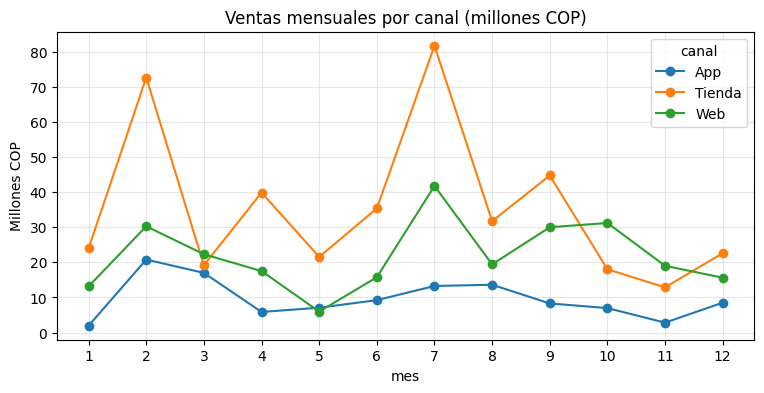

In [19]:
ventas_mes = pd.read_sql("""
SELECT d.mes, f.canal, SUM(f.total)/1e6 AS ventas_millones
FROM fact_ventas f JOIN dim_fecha d ON f.id_fecha = d.id_fecha
GROUP BY d.mes, f.canal
""", con)

ax = (ventas_mes.pivot(index="mes", columns="canal", values="ventas_millones")
      .plot(marker="o", figsize=(9, 4), title="Ventas mensuales por canal (millones COP)"))
ax.set_xticks(range(1, 13)); ax.set_ylabel("Millones COP"); ax.grid(alpha=.3)

# PARTE 2 – ANÁLISIS PREDICTIVO

Qué nos piden:
1. Selección de variables relevantes
2. Aplicación de un modelo predictivo básico
3. Visualizaciones de resultados
4. Interpretación de los resultados

Haremos **dos ejercicios**: **2A** predecir el total de cada venta y **2B** predecir la demanda por producto y mes (más realista).

## 2A. Predecir el total de cada venta

### 2A.1 Selección de variables

**Objetivo:** el `total` de la venta. **Candidatas:** cantidad, precio, descuento, mes, canal, categoría, ciudad y día de la semana.

Importante: `subtotal` y `valor_descuento` **se excluyen** porque ya se calculan con el total. Usarlas sería darle al modelo la respuesta (**fuga de datos**).

La celda calcula la **correlación** (de -1 a 1) de las variables numéricas con el total, la grafica, y muestra el total promedio por grupo para las variables de texto.

descuento         -0.007
mes                0.002
cantidad           0.334
precio_unitario    0.853
Name: total, dtype: float64

canal:
 canal
App       1312670.0
Web       1472212.0
Tienda    2244761.0
Name: total, dtype: float64

categoria:
 categoria
Accesorios         237402.0
Audio              438529.0
Redes              581000.0
Almacenamiento    1086244.0
Oficina           1974528.0
Computo           4673639.0
Name: total, dtype: float64

ciudad:
 ciudad
Barranquilla     993694.0
Medellín        1453889.0
Bucaramanga     1785230.0
Bogotá          1800028.0
Cali            2183674.0
Cartagena       2402040.0
Name: total, dtype: float64

dia_semana:
 dia_semana
Monday       1165187.0
Thursday     1387504.0
Friday       1613422.0
Tuesday      1803637.0
Sunday       1943948.0
Saturday     2116033.0
Wednesday    2347759.0
Name: total, dtype: float64


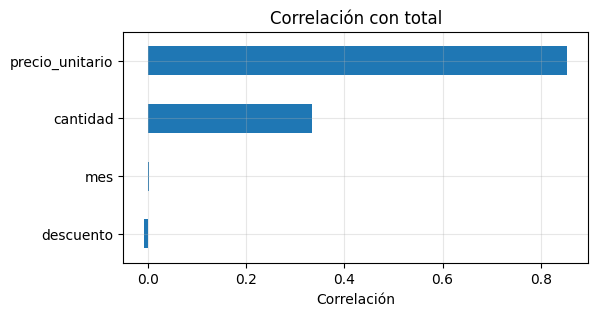

In [20]:
# Paso 1: seleccionar variables para predecir "total"
import matplotlib.pyplot as plt

# 1) Objetivo (lo que queremos predecir) y candidatas (lo que usaríamos para predecir)
objetivo = "total"
candidatas = ["cantidad", "precio_unitario", "descuento", "mes",
              "canal", "categoria", "ciudad", "dia_semana"]

# 2) Variables que NO se pueden usar: ya contienen la respuesta (fuga de datos)
excluidas = ["subtotal", "valor_descuento"]

# 3) Correlación de las numéricas con el total
numericas = ["cantidad", "precio_unitario", "descuento", "mes"]
corr = df[numericas + [objetivo]].corr()[objetivo].drop(objetivo).sort_values()
print(corr.round(3))

# 4) Gráfico de barras de la correlación
ax = corr.plot(kind="barh", figsize=(6, 3), title="Correlación con total")
ax.set_xlabel("Correlación"); ax.grid(alpha=.3)

# 5) Para las de texto: promedio del total por grupo
for col in ["canal", "categoria", "ciudad", "dia_semana"]:
    print(f"\n{col}:\n", df.groupby(col)[objetivo].mean().round(0).sort_values())

**Qué obtuvimos**
- `precio_unitario`: correlación **0.85** (la más fuerte).
- `cantidad`: **0.33** (aporta de forma moderada).
- `descuento` (-0.01) y `mes` (0.00): prácticamente nada.
- `categoria`: Cómputo vende en promedio ~4,7 millones por venta y Accesorios ~0,2 millones, pero eso solo refleja el **precio** de los productos; repite lo que ya dice `precio_unitario`.
- `canal`, `ciudad`, `dia_semana`: muestran diferencias, pero los datos son aleatorios, así que probablemente es ruido.

**Variables elegidas:** `precio_unitario`, `cantidad` y `descuento` (por lógica de negocio, el descuento sí debería afectar el total).

### 2A.2 Primer modelo: regresión lineal

1. **X** = variables (las pistas) e **y** = `total` (lo que queremos adivinar).
2. `train_test_split` separa 80% para **entrenar** y 20% para **probar** con datos que el modelo no vio. Es como estudiar con unos ejercicios y presentar el examen con otros.
3. `LinearRegression` busca la mejor fórmula que combine las variables; `fit` es el paso de aprender.
4. Medimos con dos métricas:
   - **R²**: de 0 a 1, qué porcentaje de la variación del total explica el modelo.
   - **MAE**: error promedio en pesos.

In [21]:
# Paso 2: primer modelo (regresión lineal) con las variables elegidas
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# 1) X = variables para predecir, y = lo que queremos predecir
variables = ["precio_unitario", "cantidad", "descuento"]
X = df[variables]
y = df["total"]

# 2) Separar: 80% para entrenar, 20% para examinar el modelo con datos que no vio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Entrenamiento:", len(X_train), "filas | Prueba:", len(X_test), "filas")

# 3) Crear y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 4) Predecir sobre la parte de prueba y medir qué tan bien le fue
pred = modelo.predict(X_test)
print("R2  :", round(r2_score(y_test, pred), 3))
print("MAE :", round(mean_absolute_error(y_test, pred)), "COP")
print("Total promedio real:", round(y_test.mean()), "COP")

Entrenamiento: 364 filas | Prueba: 91 filas
R2  : 0.864
MAE : 697646 COP
Total promedio real: 1783165 COP


**Qué obtuvimos:** R² ≈ **0.86** y MAE ≈ **700 mil COP**, con un total promedio de ~1,78 millones. Explica bastante, pero el error es alto: la regresión lineal **suma** efectos, mientras que el total real es una **multiplicación** (cantidad × precio).

### 2A.3 Segundo modelo: Random Forest y comparación

El **Random Forest** crea 200 árboles de decisión (preguntas tipo "¿precio mayor a 1 millón?") y promedia sus respuestas. Puede aprender combinaciones, como precio × cantidad. Se evalúa con el **mismo examen** (`X_test`) para comparar de forma justa, y también se muestra qué variables usó más (`feature_importances_`).

In [22]:
# Paso 3: segundo modelo (Random Forest) y comparación con la regresión lineal
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

# 1) Crear y entrenar el bosque (usa los mismos X_train / y_train del Paso 2)
bosque = RandomForestRegressor(n_estimators=200, random_state=42)
bosque.fit(X_train, y_train)
pred_bosque = bosque.predict(X_test)

# 2) Tabla comparativa de los dos modelos
comparacion = pd.DataFrame({
    "modelo": ["Regresión lineal", "Random Forest"],
    "R2":  [r2_score(y_test, pred), r2_score(y_test, pred_bosque)],
    "MAE": [mean_absolute_error(y_test, pred), mean_absolute_error(y_test, pred_bosque)],
}).round(3)
print(comparacion)

# 3) Qué variables usó más el bosque para decidir
importancia = pd.Series(bosque.feature_importances_, index=variables).sort_values(ascending=False)
print("\nImportancia de variables:")
print(importancia.round(3))

             modelo     R2         MAE
0  Regresión lineal  0.864  697646.192
1     Random Forest  1.000   27515.701

Importancia de variables:
precio_unitario    0.741
cantidad           0.254
descuento          0.005
dtype: float64


**Qué obtuvimos**

| Modelo | R² | MAE (COP) |
|---|---|---|
| Regresión lineal | 0.86 | ~700.000 |
| Random Forest | 1.00 | ~27.500 |

Importancia: `precio_unitario` ~74%, `cantidad` ~25%, `descuento` ~0,5%.

⚠️ **Ojo:** un R² de 1.00 **no** significa que el modelo sea perfecto para el mundo real. El total se calcula con una **fórmula exacta** (cantidad × precio × (1 − descuento)) y con solo 10 precios y 5 cantidades posibles, el bosque básicamente la **memoriza**.

### 2A.4 Visualizaciones

- **Real vs. predicho** (dos primeros gráficos): cada punto es una venta de la prueba. La línea roja es la predicción perfecta; entre más cerca esté el punto, mejor.
- **Importancia de variables** (tercero): cuánto pesó cada variable en el bosque.

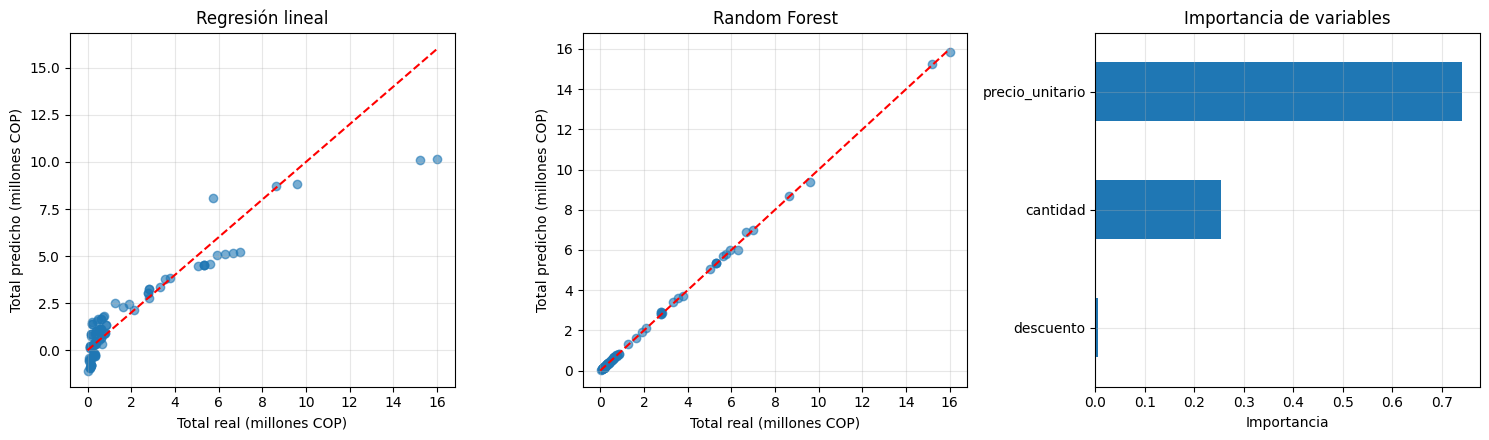

In [23]:
# Paso 4: gráficos de resultados
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))

# Gráficos 1 y 2: real vs predicho (si fuera perfecto, los puntos caen sobre la línea roja)
maximo = max(y_test.max(), pred.max()) / 1e6
for eje, predicho, titulo in [(ejes[0], pred, "Regresión lineal"),
                              (ejes[1], pred_bosque, "Random Forest")]:
    eje.scatter(y_test / 1e6, predicho / 1e6, alpha=.6)
    eje.plot([0, maximo], [0, maximo], color="red", linestyle="--")
    eje.set_title(titulo)
    eje.set_xlabel("Total real (millones COP)")
    eje.set_ylabel("Total predicho (millones COP)")
    eje.grid(alpha=.3)

# Gráfico 3: importancia de variables del bosque
importancia.sort_values().plot(kind="barh", ax=ejes[2], title="Importancia de variables")
ejes[2].set_xlabel("Importancia")
ejes[2].grid(alpha=.3)

plt.tight_layout()
plt.show()

**Qué vemos**
- **Regresión lineal:** los puntos se dispersan; en las ventas grandes (15 a 16 millones) predice cerca de 10, y en las pequeñas llega a predecir valores **negativos**, algo sin sentido para una venta.
- **Random Forest:** todos los puntos caen sobre la línea roja.
- **Importancia:** `precio_unitario` y `cantidad` concentran casi todo.

### 2A.5 Interpretación del ejercicio A
- Variables elegidas: `precio_unitario`, `cantidad`, `descuento`. Se excluyeron `subtotal` y `valor_descuento` por fuga de datos.
- La regresión lineal explica cerca del 86% de la variación pero se equivoca ~700 mil COP en promedio.
- El Random Forest llega a R² = 1.00 porque aprende la fórmula con la que se calcula el total, no el comportamiento de los clientes.
- El valor de una venta depende sobre todo del **producto** (precio) y de **cuántas unidades** se llevan; el descuento pesa muy poco.

## 2B. Predecir la demanda (unidades por producto y mes)

Este ejercicio es **más realista**: no hay una fórmula exacta que el modelo pueda memorizar.

### 2B.1 Construir la tabla de demanda

- `groupby` + `agg` funciona como una **tabla dinámica de Excel**: suma las unidades y cuenta las ventas por producto y mes.
- Si un producto no se vendió en un mes, esa fila no existe. Creamos todas las combinaciones (10 productos × 12 meses) con `merge(how="cross")` y rellenamos con **0**, para que el modelo sepa que la demanda fue cero.
- `pivot` muestra el resultado como tabla (productos en filas, meses en columnas).

In [24]:
# Demanda: unidades vendidas por producto y mes
import pandas as pd

# 1) Sumar las unidades de cada producto en cada mes
demanda = (df.groupby(["id_producto", "nombre", "categoria", "precio_unitario", "mes"], as_index=False)
             .agg(unidades=("cantidad", "sum"),
                  ventas=("id_venta", "count")))

# 2) Si un producto no se vendió en un mes, no aparece: lo agregamos con 0 unidades
productos_info = demanda[["id_producto", "nombre", "categoria", "precio_unitario"]].drop_duplicates()
grilla = productos_info.merge(pd.DataFrame({"mes": range(1, 13)}), how="cross")
demanda = (grilla.merge(demanda[["id_producto", "mes", "unidades", "ventas"]],
                        on=["id_producto", "mes"], how="left")
                 .fillna({"unidades": 0, "ventas": 0})
                 .astype({"unidades": int, "ventas": int}))

print(demanda.shape)
print(demanda["unidades"].describe().round(2))
print(demanda.pivot(index="nombre", columns="mes", values="unidades"))

(120, 7)
count    120.00
mean      11.53
std        7.18
min        0.00
25%        6.00
50%       11.00
75%       16.00
max       33.00
Name: unidades, dtype: float64
mes            1   2   3   4   5   6   7   8   9   10  11  12
nombre                                                       
Audífonos      14  11  12   2  16  22  19   6   1  11  26  19
Cámara Web     12  32  23  16   6  14   5  11  14  10   8   0
Disco SSD 1TB   5   7   6  11   9  24   5  10   9  23  13   4
Impresora      25  21  14   7   4   7  18  24  24   8   7  12
Monitor 24"    16  17  10  19   5   5  12  18   5   4   2   2
Mouse          14  11   3  28  13   1  16  16  13   4  12  24
Portátil        0  14   4  11   4   5  22   4  12   6   4   4
Router WiFi    12  11  14  10  13   8  12  15  13  13   6   6
Tablet          3  33  16   3   4  18  29  11  17  12   4  14
Teclado         6  16  11   0  17   7   6  12   6  14  15  10


**Qué obtuvimos:** 120 filas (10 × 12). Unidades por producto y mes: promedio ~11,5, entre 0 y 33. La demanda salta mucho de un mes a otro (por ejemplo, la Tablet vende 33 unidades en febrero y 3 en enero).

### 2B.2 Variables, separación por tiempo y modelos

- **`unidades_mes_anterior`**: lo vendido el mes anterior por el mismo producto (`shift(1)` desplaza la columna un mes). Por eso el mes 1 se descarta.
- **Variables:** `precio_unitario`, `mes` y `unidades_mes_anterior`.
- **Separación por tiempo:** se entrena con los meses 2 a 9 y se prueba con los meses 10 a 12. No se mezcla al azar porque en la vida real predecimos el futuro con datos del pasado.
- **Referencia (baseline):** predecir el promedio histórico de cada producto. Un modelo solo vale la pena si le gana a esta referencia.
- Se entrenan una regresión lineal y un Random Forest con `max_depth=3` para que no memorice con tan pocas filas.

In [25]:
# Demanda, Paso 2: variables, separación por tiempo y modelos
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# 1) Nueva variable: las unidades que se vendieron el mes anterior del mismo producto
demanda = demanda.sort_values(["id_producto", "mes"])
demanda["unidades_mes_anterior"] = demanda.groupby("id_producto")["unidades"].shift(1)
datos = demanda.dropna(subset=["unidades_mes_anterior"])   # el mes 1 no tiene mes anterior

# 2) Variables para predecir (X) y lo que queremos predecir (y)
variables_d = ["precio_unitario", "mes", "unidades_mes_anterior"]

# 3) Separar por tiempo: entrenar con meses 2-9, probar con meses 10-12
#    (no al azar: en la vida real predecimos el futuro con datos del pasado)
train = datos[datos["mes"] <= 9]
test = datos[datos["mes"] >= 10]
Xd_train, yd_train = train[variables_d], train["unidades"]
Xd_test, yd_test = test[variables_d], test["unidades"]
print("Entrenamiento:", len(train), "filas | Prueba:", len(test), "filas")

# 4) Referencia simple: "predigo el promedio de unidades de cada producto en el entrenamiento"
promedio_producto = train.groupby("id_producto")["unidades"].mean()
pred_base = test["id_producto"].map(promedio_producto)

# 5) Entrenar los dos modelos
lineal_d = LinearRegression().fit(Xd_train, yd_train)
bosque_d = RandomForestRegressor(n_estimators=200, max_depth=3, random_state=42).fit(Xd_train, yd_train)
pred_lineal_d = lineal_d.predict(Xd_test)
pred_bosque_d = bosque_d.predict(Xd_test)

# 6) Comparar
resultados = pd.DataFrame({
    "modelo": ["Promedio por producto (referencia)", "Regresión lineal", "Random Forest"],
    "R2":  [r2_score(yd_test, p) for p in (pred_base, pred_lineal_d, pred_bosque_d)],
    "MAE": [mean_absolute_error(yd_test, p) for p in (pred_base, pred_lineal_d, pred_bosque_d)],
}).round(3)
print(resultados)
print("\nUnidades promedio reales en la prueba:", round(yd_test.mean(), 2))

Entrenamiento: 80 filas | Prueba: 30 filas
                               modelo     R2    MAE
0  Promedio por producto (referencia) -0.332  6.467
1                    Regresión lineal  0.034  5.274
2                       Random Forest -0.114  5.635

Unidades promedio reales en la prueba: 9.9


**Qué obtuvimos** (80 filas de entrenamiento, 30 de prueba)

| Modelo | R² | MAE (unidades) |
|---|---|---|
| Promedio por producto (referencia) | -0.33 | 6.47 |
| Regresión lineal | 0.03 | 5.27 |
| Random Forest | -0.11 | 5.64 |

Un R² cercano a 0 o negativo significa que el modelo **no predice mejor que usar el promedio**. El error (~5 unidades) es cerca del 50% del promedio real (~10). Los modelos le ganan por poco a la referencia, pero no se puede decir que hayan encontrado un patrón.

### 2B.3 Visualizaciones

- **Real vs. predicho:** si el modelo acertara, los puntos formarían una diagonal sobre la línea roja. Si quedan en una franja horizontal, el modelo predice casi siempre lo mismo.
- **Importancia de variables:** qué variables usó más el bosque. Con datos sin patrón, esto mide qué variable le sirvió para "acomodarse" al entrenamiento, no que realmente prediga.

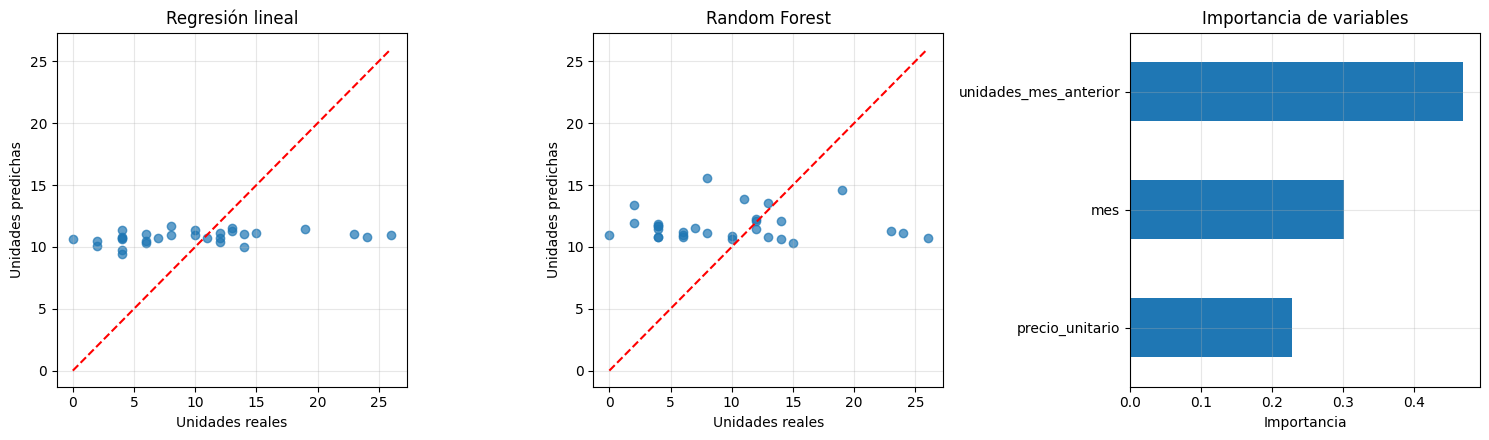

unidades_mes_anterior    0.470
mes                      0.302
precio_unitario          0.229
dtype: float64


In [26]:
# Demanda, Paso 3: gráficos de resultados
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))

# Gráficos 1 y 2: unidades reales vs predichas (la línea roja sería la predicción perfecta)
maximo = max(yd_test.max(), pred_lineal_d.max(), pred_bosque_d.max())
for eje, predicho, titulo in [(ejes[0], pred_lineal_d, "Regresión lineal"),
                              (ejes[1], pred_bosque_d, "Random Forest")]:
    eje.scatter(yd_test, predicho, alpha=.7)
    eje.plot([0, maximo], [0, maximo], color="red", linestyle="--")
    eje.set_title(titulo)
    eje.set_xlabel("Unidades reales")
    eje.set_ylabel("Unidades predichas")
    eje.grid(alpha=.3)

# Gráfico 3: importancia de variables del bosque
importancia_d = pd.Series(bosque_d.feature_importances_, index=variables_d).sort_values()
importancia_d.plot(kind="barh", ax=ejes[2], title="Importancia de variables")
ejes[2].set_xlabel("Importancia")
ejes[2].grid(alpha=.3)

plt.tight_layout()
plt.show()
print(importancia_d.sort_values(ascending=False).round(3))

**Qué vemos**
- **Regresión lineal:** los puntos forman una línea casi plana alrededor de 10-11 unidades. Predice prácticamente el promedio para todo y falla en los extremos (reales de 0 y de 25 reciben la misma predicción).
- **Random Forest:** se mueve un poco más (entre ~10 y ~15), pero sigue lejos de la diagonal.
- **Importancia:** `unidades_mes_anterior` ~0.47, `mes` ~0.30, `precio_unitario` ~0.23. Está repartida, sin una variable dominante: señal de que ninguna tiene poder real.

# Conclusiones generales

**Ejercicio A (total de la venta)**
- Las variables relevantes son `precio_unitario` (~74% de importancia) y `cantidad` (~25%); el descuento pesa ~0,5%.
- La regresión lineal logra R² = 0.86 con un error de ~700 mil COP. El Random Forest llega a R² = 1.00 porque el total es una fórmula exacta: aprende la regla, no el comportamiento de los clientes.

**Ejercicio B (demanda por producto y mes)**
- Con datos de un solo año y 30 filas de prueba, ningún modelo explica la demanda (R² entre -0.11 y 0.03; error de ~5 unidades sobre un promedio de ~10).
- Es coherente con que las ventas del taller se **generaron al azar**: no hay patrones por producto ni por mes que aprender. El análisis funciona como debe: no inventa señal donde no la hay.

**Lectura general**
- Un R² de 1.00 puede ser engañoso, y un R² cercano a 0 es un resultado válido cuando los datos no tienen patrón.
- Es clave **evaluar siempre con datos que el modelo no vio** y comparar contra una referencia simple.

**Limitaciones y mejoras**
- Pocos datos (455 ventas, un solo año) y una sola separación entrenamiento/prueba; sería mejor usar validación cruzada.
- Con datos reales se podrían agregar variables como promociones, festivos, inventario y varios años de historia para capturar estacionalidad.